# 01 · Data Exploration
## DSA 4050-XA CAT 2: Image Classification with PyTorch

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Lecturer** | Dr. Alex Wambua |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `01_data_exploration.ipynb` |
| **CAT requirement** | 1) Dataset subclass · 2) data augmentation |

### Objective
Understand the data before modelling: the classes and their balance, the images (size, colour, examples), and the pixel statistics. Then build and test the **custom `Dataset` class** and the **data-augmentation pipeline**, and create the **5 cross-validation folds** used by every later notebook.

### Inputs
- `train/<id>.png` (50,000 images), `Train.csv` (4,000 labelled ids), `Test.csv` (46,000 ids to predict)

### Outputs
- `data/processed/train_folds.csv` (fold number for every labelled image)
- `01_*` figures and tables, key numbers in `results.json`

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
# 1. Connect Google Drive (the CAT data and all project outputs live there)
from google.colab import drive
drive.mount("/content/drive")

# 2. Make the shared helper module importable
import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/cat2-image-classification/src")

# 3. Import helpers and fix the random seed
import importlib
import cat2_utils as cu
importlib.reload(cu)
cu.set_seed()

# 4. Name of THIS notebook (every saved figure/table/result is tagged with it)
NOTEBOOK = "01_data_exploration"
PATHS = cu.PATHS
print("Project root:", cu.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/cat2-image-classification


In [2]:
# Libraries used in this notebook
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import StratifiedKFold

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
GREEN = "#2E7D6B"

In [3]:
# The lecturer's shared folder: the "Advanced ML" shortcut in My Drive
DATA_SOURCE = "/content/drive/MyDrive/Advanced ML"

# Copy + unzip the images to local disk (fast; once per session)
DATA_DIR = Path(cu.restore_data(DATA_SOURCE))
IMG_DIR = DATA_DIR / "train"

Source folder: /content/drive/MyDrive/Advanced ML
Unzipped 50,000 images to /content/cat2_data/train


## 1 · The label files
`Train.csv` gives an image id and its class; `Test.csv` gives the ids we must predict (its `label` column is empty).

In [4]:
train_df, test_df = cu.load_labels(DATA_DIR)
print("Train.csv:", train_df.shape, "| Test.csv:", test_df.shape)
print("Classes:", cu.CLASSES)
display(train_df.head())
display(test_df.head())

Train.csv: (4000, 3) | Test.csv: (46000, 2)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,id,label,target
0,44011,truck,9
1,40500,deer,4
2,19479,horse,7
3,3682,ship,8
4,7367,ship,8


,id,label
0,33680,NaN
1,24631,NaN
2,34739,NaN
3,15922,NaN
4,44282,NaN


In [5]:
# Checks: every id has an image, no id is in both files, no duplicates
on_disk = {int(p.stem) for p in IMG_DIR.glob("*.png")}
checks = {
    "images on disk": len(on_disk),
    "train ids missing an image": int((~train_df["id"].isin(on_disk)).sum()),
    "test ids missing an image": int((~test_df["id"].isin(on_disk)).sum()),
    "ids in both train and test": len(set(train_df["id"]) & set(test_df["id"])),
    "duplicate train ids": int(train_df["id"].duplicated().sum()),
    "duplicate test ids": int(test_df["id"].duplicated().sum()),
    "test labels already filled": int(test_df["label"].notna().sum()),
}
checks_df = pd.DataFrame(checks.items(), columns=["check", "value"])
cu.save_table(checks_df, "01_integrity_checks", NOTEBOOK, caption="Data integrity checks.")
for k, v in checks.items():
    cu.log_result("check_" + k.replace(" ", "_"), v, NOTEBOOK)
checks_df

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/01_integrity_checks.csv
Result logged: check_images_on_disk = 50000
Result logged: check_train_ids_missing_an_image = 0
Result logged: check_test_ids_missing_an_image = 0
Result logged: check_ids_in_both_train_and_test = 0
Result logged: check_duplicate_train_ids = 0
Result logged: check_duplicate_test_ids = 0
Result logged: check_test_labels_already_filled = 0


,check,value
0,images on disk,50000
1,train ids missing an image,0
2,test ids missing an image,0
3,ids in both train and test,0
4,duplicate train ids,0
5,duplicate test ids,0
6,test labels already filled,0


**Interpretation:** the data is clean and consistent: all **50,000** images exist, every id in both CSVs has a matching file, there are **no duplicates**, **no overlap** between the 4,000 training ids and the 46,000 test ids, and the test `label` column is empty, as expected.

## 2 · Class balance
Only **4,000 labelled images** are available for **46,000 predictions**: the labelled set is about 8% of the data. Class balance tells us whether accuracy is a fair metric.

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/01_class_balance.png


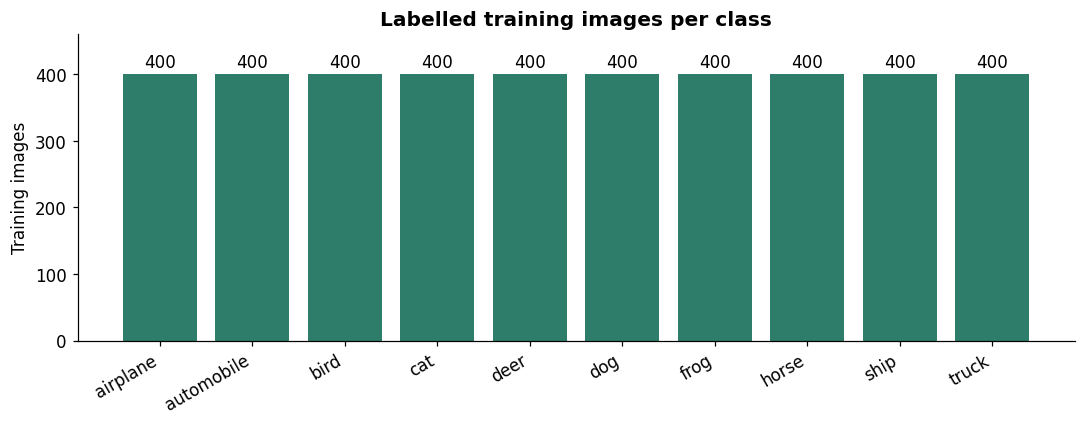

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/01_class_counts.csv
Result logged: n_train_labelled = 4000
Result logged: n_test = 46000
Result logged: images_per_class = {'airplane': 400, 'automobile': 400, 'bird': 400, 'cat': 400, 'deer': 400, 'dog': 400, 'frog': 400, 'horse': 400, 'ship': 400, 'truck': 400}
Result logged: random_baseline_accuracy = 0.1


In [6]:
counts = train_df["label"].value_counts().reindex(cu.CLASSES)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(counts.index, counts.values, color=GREEN)
ax.bar_label(bars, padding=2)
ax.set_ylabel("Training images")
ax.set_title("Labelled training images per class")
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
cu.save_figure(fig, "01_class_balance", NOTEBOOK, caption="Number of labelled training images per class.")
plt.show()

cu.save_table(counts.rename_axis("class").reset_index(name="images"), "01_class_counts", NOTEBOOK,
              caption="Labelled training images per class.")
cu.log_result("n_train_labelled", len(train_df), NOTEBOOK)
cu.log_result("n_test", len(test_df), NOTEBOOK)
cu.log_result("images_per_class", counts.to_dict(), NOTEBOOK)
cu.log_result("random_baseline_accuracy", round(1 / len(cu.CLASSES), 3), NOTEBOOK)

**Interpretation:** the classes are **perfectly balanced** at **400 images each**, so accuracy is a fair metric (no class dominates) and random guessing scores **10%**. The challenge is the size: only **8%** of the 50,000 images are labelled, so the model must generalise from very few examples per class.

## 3 · The images
All 50,000 images are loaded into memory once as a NumPy array (about 150 MB), which is much faster than re-reading PNG files during training.

In [7]:
t0 = time.time()
X_train = cu.load_images(train_df["id"], IMG_DIR)          # (4000, H, W, 3) uint8
X_test = cu.load_images(test_df["id"], IMG_DIR)            # (46000, H, W, 3) uint8
print(f"Loaded in {time.time() - t0:.0f}s | train {X_train.shape} | test {X_test.shape} | dtype {X_train.dtype}")

shapes = {X_train.shape[1:], X_test.shape[1:]}
cu.log_result("image_shape", str(list(shapes)[0]) if len(shapes) == 1 else str(shapes), NOTEBOOK)
print("Distinct image shapes:", shapes)

Loaded in 14s | train (4000, 32, 32, 3) | test (46000, 32, 32, 3) | dtype uint8
Result logged: image_shape = (32, 32, 3)
Distinct image shapes: {(32, 32, 3)}


Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/01_examples_per_class.png


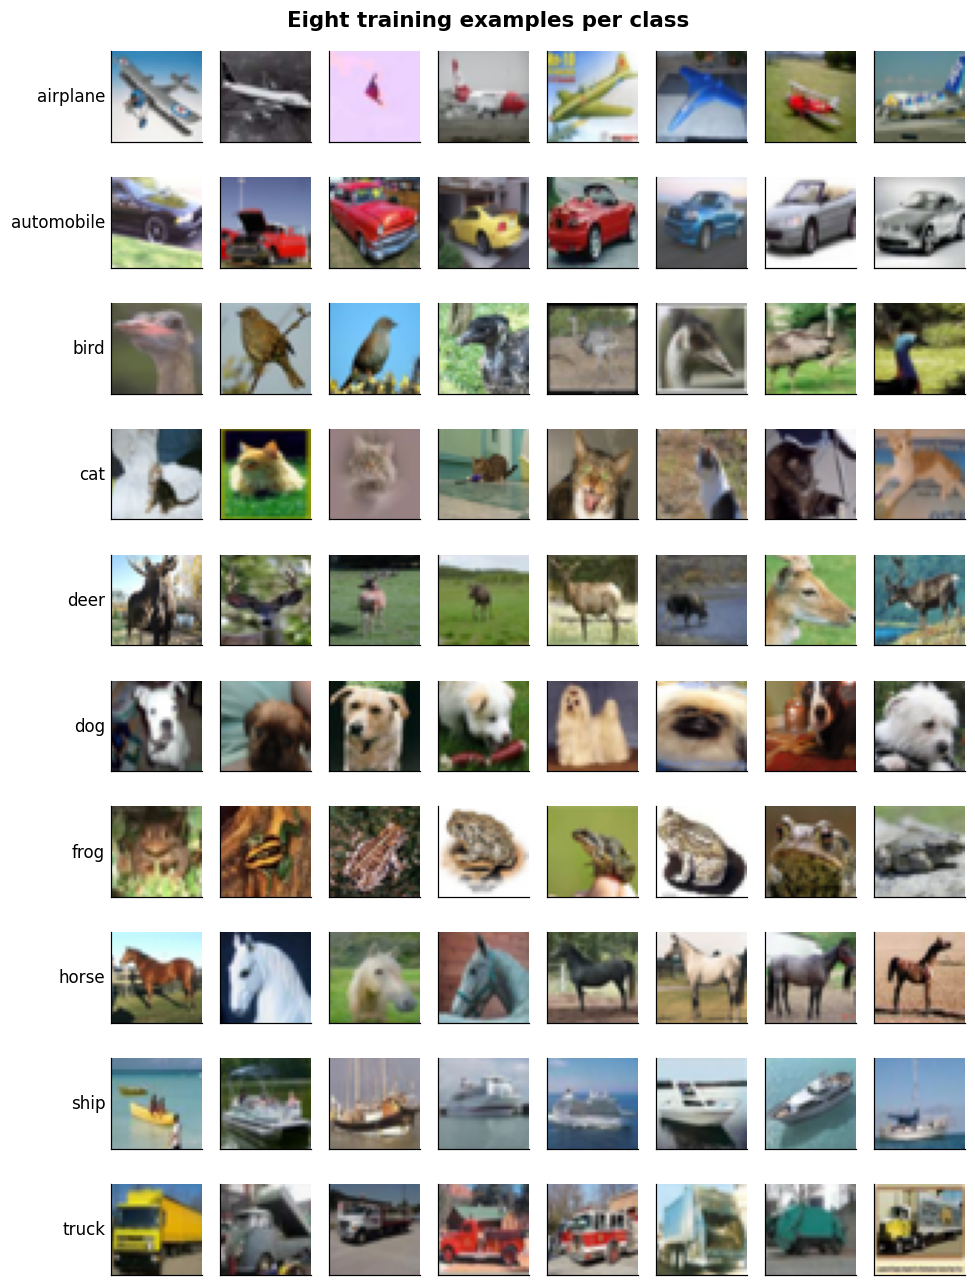

In [8]:
# 8 random examples of every class
rng = np.random.default_rng(cu.SEED)
fig, axes = plt.subplots(len(cu.CLASSES), 8, figsize=(9, 12))
for r, cls in enumerate(cu.CLASSES):
    idx = rng.choice(np.where(train_df["label"].to_numpy() == cls)[0], 8, replace=False)
    for c_, i in enumerate(idx):
        axes[r, c_].imshow(X_train[i])
        axes[r, c_].set_xticks([]); axes[r, c_].set_yticks([])
    axes[r, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=11)
fig.suptitle("Eight training examples per class", fontsize=14, fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "01_examples_per_class", NOTEBOOK, caption="Eight random training images of each class.")
plt.show()

**Interpretation:** every image is a tiny **32×32 colour photo** (identical shape for all 50,000), so fine detail is lost and objects are often only a few pixels wide. Within each class the variety is large: different breeds, colours, viewpoints, close-ups vs distant shots, and cluttered backgrounds. Several pairs look alike at this resolution, notably **cat / dog**, **automobile / truck**, **deer / horse** and **bird / airplane** (small object against the sky); these are expected to be the main sources of error.

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/01_average_image_per_class.png


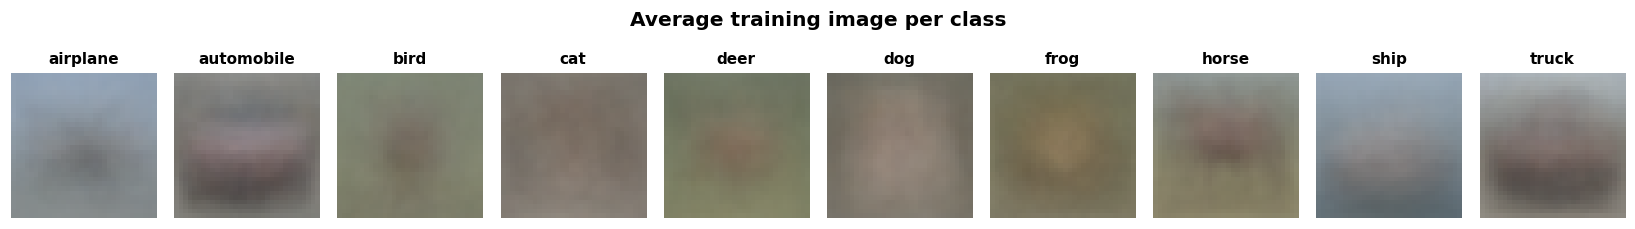

In [9]:
# Average image per class: shows typical colours and layout (e.g. blue sky/sea backgrounds)
fig, axes = plt.subplots(1, len(cu.CLASSES), figsize=(15, 2.2))
for ax, cls in zip(axes, cu.CLASSES):
    ax.imshow(X_train[train_df["label"].to_numpy() == cls].mean(axis=0).astype(np.uint8))
    ax.set_title(cls, fontsize=10); ax.axis("off")
fig.suptitle("Average training image per class", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "01_average_image_per_class", NOTEBOOK, caption="Pixel-wise average of the training images of each class.")
plt.show()

**Interpretation:** the averages reveal typical **backgrounds** rather than objects: **airplane** and **ship** are dominated by blue-grey sky and water; **deer**, **frog**, **horse** and **bird** by green and brown vegetation; **automobile** and **truck** show a centred, wide vehicle shape on grey road. Colour and background therefore help, but they cannot separate classes with similar settings (cat vs dog, automobile vs truck), so the model must learn **shape**, which motivates convolutional networks and, given only 400 images per class, **pretrained** features.

## 4 · Pixel statistics
Mean and standard deviation of each colour channel. A model trained from scratch is normalised with **these** statistics; pretrained networks use the ImageNet statistics they were trained with. Train and test should look alike (same distribution).

In [10]:
def channel_stats(X):
    x = X.reshape(-1, 3).astype(np.float64) / 255
    return x.mean(0), x.std(0)

m_tr, s_tr = channel_stats(X_train)
m_te, s_te = channel_stats(X_test)
stats = pd.DataFrame({"channel": ["R", "G", "B"], "train_mean": m_tr, "train_std": s_tr,
                      "test_mean": m_te, "test_std": s_te}).round(4)
cu.save_table(stats, "01_pixel_stats", NOTEBOOK, caption="Per-channel mean and standard deviation (pixels scaled 0-1).")
np.save(os.path.join(PATHS["processed"], "train_mean_std.npy"), np.stack([m_tr, s_tr]))
cu.log_result("train_channel_mean", m_tr.round(4).tolist(), NOTEBOOK)
cu.log_result("train_channel_std", s_tr.round(4).tolist(), NOTEBOOK)
stats

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/01_pixel_stats.csv
Result logged: train_channel_mean = [0.4913, 0.4839, 0.4477]
Result logged: train_channel_std = [0.2463, 0.2423, 0.2616]


,channel,train_mean,train_std,test_mean,test_std
0,R,0.4913,0.2463,0.4914,0.2471
1,G,0.4839,0.2423,0.4820,0.2436
2,B,0.4477,0.2616,0.4464,0.2616


**Interpretation:** the training and test images have **almost identical colour statistics** (means differ by at most 0.002, standard deviations by under 0.002), confirming the 4,000 labelled images come from the same distribution as the 46,000 to be predicted. These statistics are used to normalise the from-scratch baseline in notebook 02.

## 5 · The custom `Dataset` class (CAT requirement 1)
`cu.CIFARCSVDataset` **subclasses `torch.utils.data.Dataset`** and implements the three required methods:

| Method | What it does |
|---|---|
| `__init__(df, image_dir, transform, images)` | Stores the ids, the numeric labels (or −1 for unlabelled test images), the transform and, optionally, the pre-loaded image array |
| `__len__()` | Number of images |
| `__getitem__(idx)` | Loads image `idx` (from memory, or from `<id>.png` on disk), applies the transform, and returns `(image_tensor, label)` |

A `DataLoader` then batches and shuffles these items for training. Below, the class is tested both ways (from disk and from memory) and a batch is drawn.

In [11]:
import inspect
print(inspect.getsource(cu.CIFARCSVDataset))

    class CIFARCSVDataset(Dataset):
        """
        Custom PyTorch Dataset (subclasses torch.utils.data.Dataset).

        Each item is (image_tensor, label). Images are looked up by their id in a
        DataFrame (Train.csv or Test.csv); test images have no label, so -1 is
        returned instead.

        Parameters
        ----------
        df        : DataFrame with an 'id' column (and 'target' for labelled data)
        image_dir : folder holding <id>.png files
        transform : torchvision transform applied to each PIL image (augmentation
                    for training, plain preprocessing for validation/test)
        images    : optional pre-loaded uint8 array (N, H, W, 3) in the same order
                    as df. The whole dataset is only ~150 MB in memory, so
                    pre-loading avoids re-reading thousands of PNGs every epoch.
        """

        def __init__(self, df: pd.DataFrame, image_dir=None, transform=None, images: np.ndarray = None):
        

In [12]:
plain = cu.build_transforms(train=False, img_size=32)
ds_disk = cu.CIFARCSVDataset(train_df, image_dir=IMG_DIR, transform=plain)          # reads PNGs
ds_mem = cu.CIFARCSVDataset(train_df, transform=plain, images=X_train)              # pre-loaded
ds_test = cu.CIFARCSVDataset(test_df, transform=plain, images=X_test)

x0, y0 = ds_disk[0]
x1, y1 = ds_mem[0]
print("is a torch Dataset:", isinstance(ds_mem, torch.utils.data.Dataset))
print("len(train) =", len(ds_mem), "| len(test) =", len(ds_test))
print("item 0:", tuple(x0.shape), x0.dtype, "label", y0, f"({cu.CLASSES[y0]})")
print("disk and memory versions identical:", torch.allclose(x0, x1))
print("test item label:", ds_test[0][1], "(-1 = unknown)")

loader = cu.make_loader(ds_mem, batch_size=128, shuffle=True)
t0 = time.time(); xb, yb = next(iter(loader))
print(f"one batch: images {tuple(xb.shape)}, labels {tuple(yb.shape)} ({time.time() - t0:.2f}s)")

is a torch Dataset: True
len(train) = 4000 | len(test) = 46000
item 0: (3, 32, 32) torch.float32 label 9 (truck)
disk and memory versions identical: True
test item label: -1 (-1 = unknown)
one batch: images (128, 3, 32, 32), labels (128,) (0.36s)


## 6 · Data augmentation (CAT requirement 2)
With only 400 images per class, the model would quickly memorise the training set. **Augmentation** creates a slightly different version of every image in every epoch:

| Operation | Effect |
|---|---|
| Random crop (4-px reflect padding) | Small shifts of the object |
| Horizontal flip | Mirror image (orientation does not change the class) |
| **RandAugment** (2 operations, magnitude *m*) | Randomly picks from rotation, shear, colour, contrast, brightness, sharpness, posterise, etc. |
| Random erasing | Hides a random patch, so the model must use the whole object |

The **magnitude** *m* is one of the hyper-parameters tuned later. Validation and test images are **never** augmented.

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/01_augmentation_examples.png


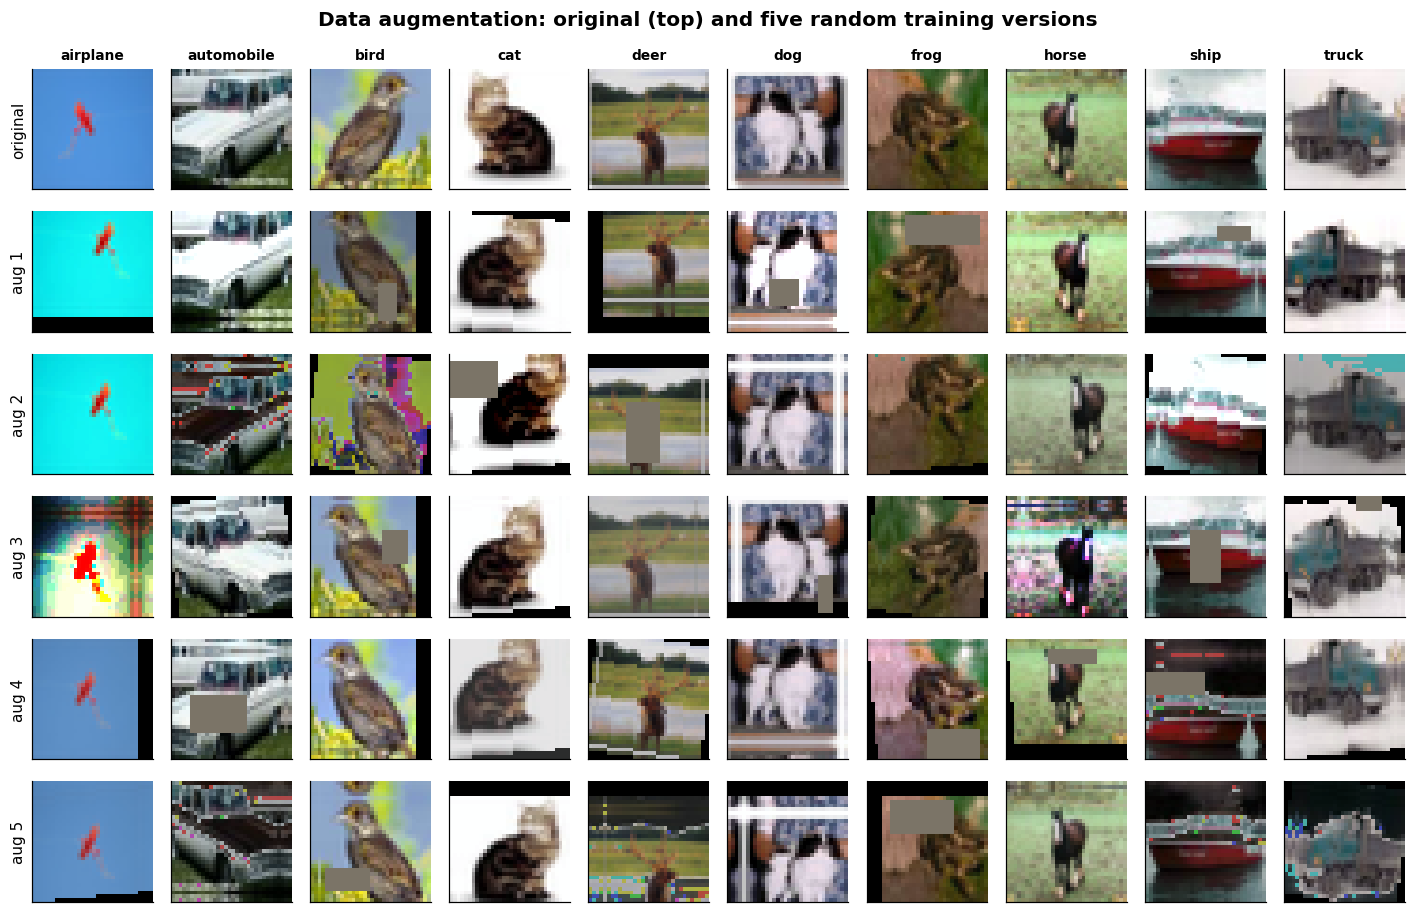

In [13]:
# One image per class (top row) and five augmented versions of each
aug = cu.build_transforms(train=True, img_size=32, randaug_magnitude=9)
first_of_class = [int(np.where(train_df["target"] == k)[0][0]) for k in range(10)]
ds_aug = cu.CIFARCSVDataset(train_df, transform=aug, images=X_train)
torch.manual_seed(cu.SEED)
fig, axes = plt.subplots(6, 10, figsize=(13, 8.5))
for c_, i in enumerate(first_of_class):
    axes[0, c_].imshow(X_train[i]); axes[0, c_].set_title(cu.CLASSES[c_], fontsize=9)
    for r in range(1, 6):
        axes[r, c_].imshow(cu.denormalize(ds_aug[i][0]))
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("original", fontsize=10)
for r in range(1, 6):
    axes[r, 0].set_ylabel(f"aug {r}", fontsize=10)
fig.suptitle("Data augmentation: original (top) and five random training versions", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "01_augmentation_examples", NOTEBOOK, caption="Training images and five randomly augmented versions of each.")
plt.show()

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/01_randaugment_strength.png


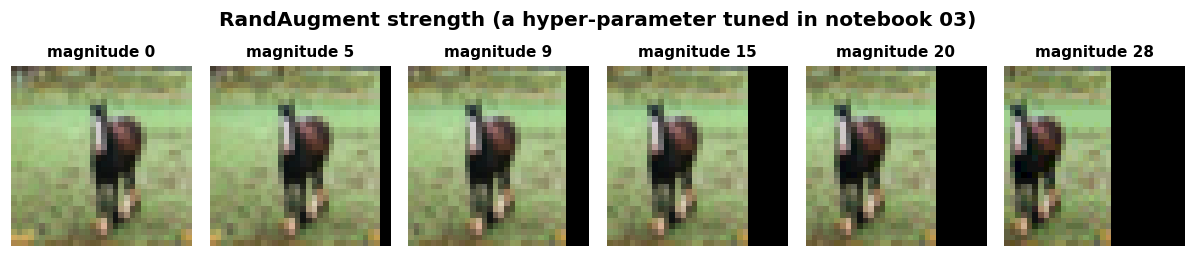

In [14]:
# Augmentation strength: the same image at increasing RandAugment magnitude
i = first_of_class[7]
fig, axes = plt.subplots(1, 6, figsize=(11, 2.4))
for ax, m in zip(axes, [0, 5, 9, 15, 20, 28]):
    torch.manual_seed(1)
    ax.imshow(cu.denormalize(cu.build_transforms(True, 32, randaug_magnitude=m, erase_prob=0)(cu.Image.fromarray(X_train[i]))))
    ax.set_title(f"magnitude {m}", fontsize=10); ax.axis("off")
fig.suptitle("RandAugment strength (a hyper-parameter tuned in notebook 03)", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "01_randaugment_strength", NOTEBOOK, caption="One image under increasing RandAugment magnitude.")
plt.show()

## 7 · Five cross-validation folds
The 4,000 labelled images are split into **5 stratified folds** (80 images per class per fold). They are used for:
- **Hyper-parameter search (notebook 03):** train on folds 1–4, validate on fold 0.
- **Final model (notebook 04):** 5 models, each validated on a different fold. Their average accuracy on unseen folds is an honest estimate of test accuracy, and the 5 models are averaged for the final predictions.

The fold file is saved so every notebook uses exactly the same split.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=cu.SEED)
train_df["fold"] = -1
for f, (_, val_idx) in enumerate(skf.split(train_df, train_df["target"])):
    train_df.loc[val_idx, "fold"] = f
train_df[["id", "label", "target", "fold"]].to_csv(os.path.join(PATHS["processed"], "train_folds.csv"), index=False)

fold_table = pd.crosstab(train_df["label"], train_df["fold"]).reindex(cu.CLASSES)
cu.save_table(fold_table.reset_index(names="class"), "01_fold_counts", NOTEBOOK, caption="Images per class in each of the 5 folds.")
fold_table

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/01_fold_counts.csv


fold,0,1,2,3,4
label,,,,,
airplane,80,80,80,80,80
automobile,80,80,80,80,80
bird,80,80,80,80,80
cat,80,80,80,80,80
deer,80,80,80,80,80
dog,80,80,80,80,80
frog,80,80,80,80,80
horse,80,80,80,80,80
ship,80,80,80,80,80


**Interpretation:** each of the 5 folds holds **exactly 80 images of every class** (800 per fold), so every validation fold is a balanced, representative sample, and all later notebooks use the same split.

## Check · Project status

In [16]:
cu.project_summary()

Project root : /content/drive/MyDrive/DSA4050/cat2-image-classification
Figures      : 5
Tables       : 5
Models       : 0
Results      : 23
Experiments  : 0


## Findings for the write-up
- **Data:** 50,000 colour images of **32×32 pixels**; **4,000 labelled** (Train.csv) and **46,000 to predict** (Test.csv). All files present, no duplicates, no overlap between train and test.
- **Balance:** 10 classes × **400 images**; random-guess accuracy is 10%. Only 8% of the images are labelled, which makes this a **low-data** problem.
- **Distribution:** training and test pixel statistics are almost identical (channel means 0.491/0.484/0.448 vs 0.491/0.482/0.446; standard deviations ≈0.25 for both), so the training images represent the test images well.
- **Visual difficulty:** large variety within classes; look-alike pairs at 32×32 (cat/dog, automobile/truck, deer/horse, bird/airplane); class averages are dominated by backgrounds (sky, water, vegetation, road).
- **Requirement 1:** `CIFARCSVDataset` subclasses `torch.utils.data.Dataset` (`__init__`, `__len__`, `__getitem__`); it returns identical tensors whether reading PNG files or a pre-loaded array, and −1 for unlabelled test images. A DataLoader batch of 128 is produced in 0.36 s.
- **Requirement 2:** training augmentation = random crop (reflect padding 4) + horizontal flip + RandAugment (2 ops, tunable magnitude) + random erasing; validation and test images are not augmented.
- **Validation design:** 5 stratified folds of 800 images (80 per class), saved for all later notebooks.

**Next notebook:** `02_baseline_cnn.ipynb`: a CNN trained from scratch, as a reference point.